# 03. Depth from a light field and extended depth of field

A point's depth is encoded in how it moves between views, and that movement shows up in two places: the $\alpha$ at which it is sharpest after refocusing, and the slope of its line in an epipolar image. This notebook runs four estimators: defocus (sharpest plane), correspondence (views that agree), the EPI slope from a structure tensor, and a fused version of the first two. The synthetic scene comes with true disparity, so we can score each method with MAE, RMSE and bad-pixel ratio. We then run the same estimators on Lego Knights, which has no ground truth, and finish with an all-in-focus image from a focal stack.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs of textures).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import lf` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lf
from lf import io as lfio, synthetic, depth, edof, utils

L_syn = synthetic.synthetic_light_field(n_views=7, size=128)
gt = L_syn.meta['gt_disparity']
alphas_syn = np.linspace(-1.5, 2.0, 15)
print(L_syn, '| ground-truth disparity range:', L_syn.meta['disparity_range'])

LightField('synthetic', angular 7x7, spatial 128x128, 3 ch) | ground-truth disparity range: (-1.0, 1.5)


## Scoring the estimators on the synthetic scene

Each estimator returns a disparity map. `depth.evaluate` compares it with the ground truth after ignoring an 8-pixel border, and by default also ignores a 3-pixel band around depth edges, where the answer is ambiguous. The `_all` numbers include the edges.

In [2]:
estimates = {
    'defocus': depth.depth_from_focus(L_syn, alphas_syn),
    'correspondence': depth.depth_from_correspondence(L_syn, alphas_syn),
    'EPI slope': depth.epi_structure_tensor_disparity(L_syn),
    'combined': depth.depth_combined(L_syn, alphas_syn),
}
print(f"{'method':16s} {'MAE':>7s} {'RMSE':>7s} {'bad (edges excl.)':>18s} {'bad (all px)':>13s}")
for name, r in estimates.items():
    m = depth.evaluate(r['disparity'], gt, border=8)
    print(f"{name:16s} {m['mae']:7.3f} {m['rmse']:7.3f} {m['bad_pixel_ratio']:18.3f} {m['bad_pixel_ratio_all']:13.3f}")

method               MAE    RMSE  bad (edges excl.)  bad (all px)
defocus            0.009   0.129              0.005         0.045
correspondence     0.115   0.467              0.061         0.155
EPI slope          0.024   0.145              0.011         0.124
combined           0.060   0.148              0.079         0.221


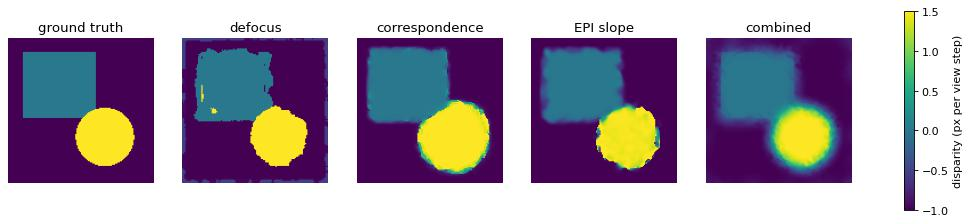

In [3]:
items = [('ground truth', gt)] + [(k, r['disparity']) for k, r in estimates.items()]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, (title, d) in zip(axes, items):
    im = ax.imshow(d, cmap='viridis', vmin=-1.0, vmax=1.5)
    ax.set_title(title); ax.axis('off')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, label='disparity (px per view step)')

Defocus is the most accurate estimator on this scene (MAE 0.009), with EPI slope second. The combined estimator is not better than defocus alone here: the correspondence cue pulls it down on the grass (see docs/07), and its all-pixel bad-pixel ratio is the highest of the four (0.22). Errors cluster at the layer boundaries, which the evaluation excludes from the bad-pixel band but the all-pixel column counts.

## Lego Knights, no ground truth

On real data we can only check the maps by eye. The wall should sit near disparity $-1$ and the knights between $0$ and $0.5$, with the same range that `refocus.SUGGESTED_ALPHA_RANGE` gives for this crop.

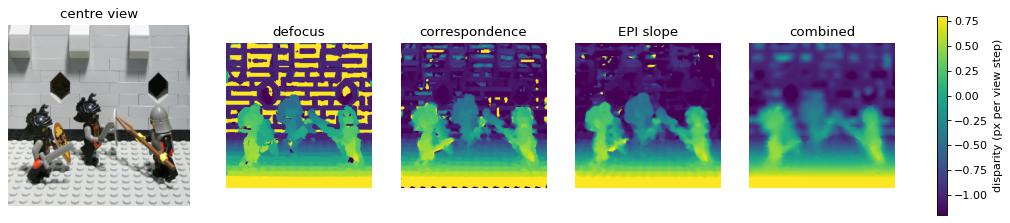

In [4]:
L_lego = lfio.load('lego', downsample=4, angular_crop=9)
alphas_lego = np.linspace(-2.0, 1.5, 15)
lego_est = {
    'defocus': depth.depth_from_focus(L_lego, alphas_lego),
    'correspondence': depth.depth_from_correspondence(L_lego, alphas_lego),
    'EPI slope': depth.epi_structure_tensor_disparity(L_lego),
    'combined': depth.depth_combined(L_lego, alphas_lego),
}
items = [('centre view', L_lego.center_view)] + [(k, r['disparity']) for k, r in lego_est.items()]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, (title, d) in zip(axes, items):
    if title == 'centre view':
        ax.imshow(np.clip(d, 0, 1))
    else:
        im = ax.imshow(d, cmap='viridis', vmin=-1.2, vmax=0.8)
    ax.set_title(title); ax.axis('off')
fig.colorbar(im, ax=axes[1:].tolist(), shrink=0.85, label='disparity (px per view step)')

The correspondence and EPI maps keep the wall dark (near $-1$) and the knights in the middle range. Defocus is the most erratic: the brick texture creates false sharpness peaks on the wall, and the combined map is the smoothest but softens the knights' outlines.

The estimator confidence tells you where to trust a map. Here is the combined confidence for the same scene.

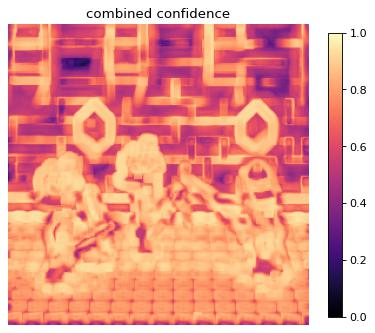

In [5]:
conf = depth.depth_combined(L_lego, alphas_lego)['confidence']
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(conf, cmap='magma', vmin=0, vmax=1)
ax.set_title('combined confidence'); ax.axis('off')
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()

Confidence is lowest along the knights' edges and at some brick joints, where the two cues disagree, and it is high on the flat baseplate and most of the wall. The fusion step weights each cue by this map.

## Bracelet (optional)

The Stanford bracelet is another gantry capture with a different depth range. If it is on disk, the cell below runs the combined estimator on it. Otherwise it prints a message.

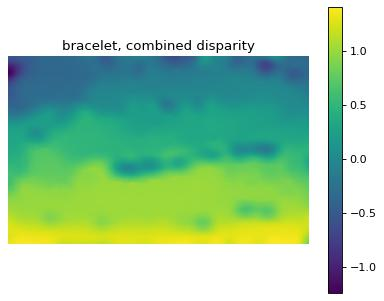

In [6]:
if lfio.available()['bracelet']:
    L_br = lfio.load('bracelet', downsample=4, angular_crop=9)
    d_br = depth.depth_combined(L_br, np.linspace(-2.0, 1.5, 15))['disparity']
    fig, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(d_br, cmap='viridis'); ax.set_title('bracelet, combined disparity'); ax.axis('off')
    fig.colorbar(im, ax=ax, shrink=0.85)
    plt.tight_layout()
else:
    print('Bracelet is not on disk; run scripts/download_data.py bracelet to enable this cell.')

## Extended depth of field

A focal stack gives an all-in-focus image: for each pixel, take the frame where it is sharpest, with soft weights so the transitions are smooth. `compare_with_stop_down` puts three images side by side: the full aperture focused on the wall, the same lens stopped down to a small disc, and the all-in-focus merge of the full light field. The stopped-down image gets synthetic noise, scaled by the lost light.

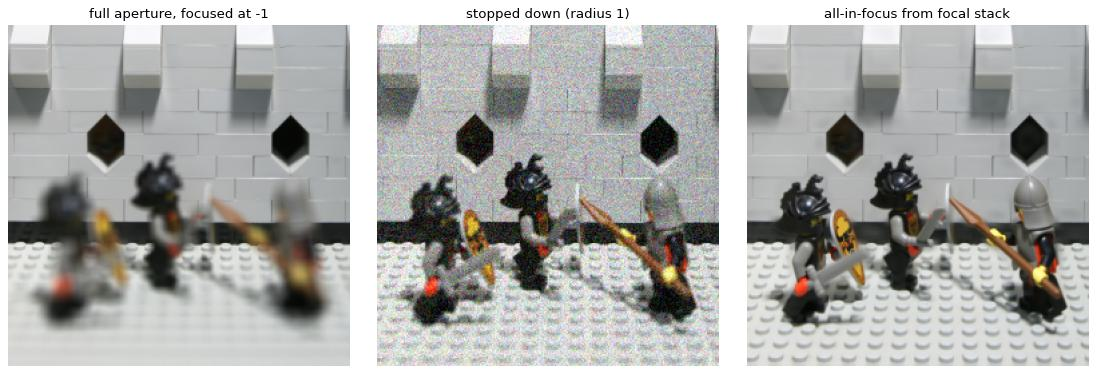

In [7]:
alphas_edof = np.linspace(-2.0, 1.5, 15)
full, stopped, aif = edof.compare_with_stop_down(L_lego, alphas_edof, small_radius=1,
                                                 noise_sigma=0.02, focus_alpha=-1.0)
panels = [('full aperture, focused at -1', full),
          ('stopped down (radius 1)', stopped),
          ('all-in-focus from focal stack', aif)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (title, img) in zip(axes, panels):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title); ax.axis('off')
plt.tight_layout()

The full aperture is smooth, and only the wall is sharp. Stopping down brings the knights into focus, but the image is grainy because the simulated noise is scaled by the light that is lost. The all-in-focus result keeps the full light and is sharp at both depths, though it may show halos where depth changes abruptly.

## Where to go next

Read [docs/06_extended_dof.md](../docs/06_extended_dof.md) for the weighting scheme and its limits, and [docs/07_depth_estimation.md](../docs/07_depth_estimation.md) for the four estimators, the confidence measures and the evaluation protocol. Notebook 04 moves from the software aperture to a programmable aperture in the camera. The matching tabs in the Streamlit explorer (`streamlit run app/streamlit_app.py`) show the depth maps with sliders.